# 09 — El entorno: cómo se relacionan los contextos entre sí

## Qué contesta este cuaderno

**Aquí no hay un solo dato del hospital.** Antes de volver a enfrentar nada contra el triage,
se conecta el entorno de Manizales consigo mismo (decisión del propietario, `docs/CONTEXTO.md`,
2026-09-29):

1. **La materia prima**: una semana por fila y cada contexto en una columna.
2. **Qué contextos comparten el calendario del año**: estacionalidad compartida.
3. **Cómo el calendario mueve el entorno**: fines de semana, festivos, quincena y noches
   festivas contra la violencia y las lesiones que registra la Policía.
4. **Cadenas con rezago**: ¿el clima precede a la circulación de virus? ¿Las vacaciones
   escolares la cortan? ¿La lluvia precede a la diarrea? ¿El ENSO mueve la lluvia de Manizales?
5. **Estados del entorno**: qué combinaciones se repiten, incluida la **«calma»**.
6. **Lo observado contra lo publicado**: `calendarios/docs/LITERATURA_ENTORNO.md`.

La idea, en palabras del propietario: los factores no actúan solos. Una población frágil, más
frío, más un virus circulando pesan más juntos que por separado. **Primero hay que saber cuándo
coinciden.**

## De dónde salen los datos

| Contexto | Archivo | Fuente oficial |
|---|---|---|
| Clima diario (lluvia con el pluviómetro roto ya corregido) | `calendarios/clima_unificado.csv.gz` | IDEAM, METAR La Nubia, NASA POWER, Open-Meteo |
| ENSO (ONI) | `calendarios/enso_oni.csv` (`calendarios/clima/enso.py`) | NOAA, Climate Prediction Center |
| IRA de la ciudad, sin el SES | `calendarios/vigilancia_sivigila_instituciones.csv.gz` | SIVIGILA 995, INS |
| EDA y eventos individuales (suicidio, violencia de género, agresiones por animales, pólvora…) | `calendarios/vigilancia_sivigila*.csv.gz` | SIVIGILA, INS |
| Lesiones personales, violencia intrafamiliar, homicidios, tránsito | `calendarios/seguridad_mindefensa.csv.gz` | Policía / MinDefensa, datos.gov.co |
| Festivos, quincena | `calendarios/calendario_Colombia.csv` | calendario oficial |
| Recesos escolares oficiales | `calendarios/calendario_escolar_manizales.csv` | resoluciones de la Secretaría de Educación de Manizales |
| Feria y eventos de la ciudad | `calendarios/eventos_manizales_2020_2026.csv` | calendario con fuente |
| Fiestas de 26 municipios de Caldas | `calendarios/fiestas_caldas_2020_2026.csv` | alcaldías, Gobernación, prensa |
| Alerta y ceniza del Nevado del Ruiz | `calendarios/vigilancia_salud_manizales_caldas.csv` | Servicio Geológico Colombiano (periodos manuales) |


In [1]:
import sys, pathlib, warnings, os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")   # silencia un aviso de scikit-learn en Windows
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import statsmodels.api as sm

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
CATEG = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
DIVERGENTE = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
SES = 170010010301
dias = pd.date_range("2015-01-01", "2026-09-20")

def a_semana(s, como="sum"):
    """Semana epidemiologica (domingo a sabado), indexada por el domingo."""
    r = getattr(s.resample("W-SAT"), como)()
    r.index = r.index - pd.Timedelta(days=6)
    return r

# ---------- clima
cl = pd.read_csv(RAIZ / "calendarios/clima_unificado.csv.gz", parse_dates=["fecha"]).set_index("fecha")
# ---------- ENSO (mensual -> diario por mes)
oni = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"])
oni_d = oni.set_index(oni.fecha.dt.to_period("M"))["oni"]
# ---------- SIVIGILA
inst = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_instituciones.csv.gz", parse_dates=["fecha_inicio_semana"])
ciudad = inst[inst.cod_upgd.ne(SES)].groupby("fecha_inicio_semana")[["consultas_ira", "consultas_todas_causas"]].sum()
vig = pd.concat([pd.read_csv(p) for p in sorted((RAIZ / "calendarios").glob("vigilancia_sivigila*.csv.gz"))
                 if "instituciones" not in p.name], ignore_index=True)
vig["fecha_inicio_semana"] = pd.to_datetime(vig["fecha_inicio_semana"])
man = vig[vig.ambito.eq("manizales")].pivot_table(index="fecha_inicio_semana", columns=["evento", "variable"], values="valor", aggfunc="sum")
# ---------- Policia
seg = pd.read_csv(RAIZ / "calendarios/seguridad_mindefensa.csv.gz", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
# ---------- calendario, escolar, eventos, fiestas, volcan
calc = pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha").reindex(dias)
esc = pd.read_csv(RAIZ / "calendarios/calendario_escolar_manizales.csv", parse_dates=["fecha_inicio", "fecha_fin"])
eventos = pd.read_csv(RAIZ / "calendarios/eventos_manizales_2020_2026.csv")
fiestas = pd.read_csv(RAIZ / "calendarios/fiestas_caldas_2020_2026.csv")
vsal = pd.read_csv(RAIZ / "calendarios/vigilancia_salud_manizales_caldas.csv")

def marcar(ini, fin):
    s = pd.Series(0.0, index=dias)
    for a, b in zip(pd.to_datetime(ini), pd.to_datetime(fin)):
        if pd.notna(a): s.loc[a: (b if pd.notna(b) else a)] = 1
    return s
receso = marcar(esc.fecha_inicio, esc.fecha_fin)
ok_ev = eventos.estado.isin(["realizado", "hibrido"])
feria = marcar(*[eventos[ok_ev & eventos.nombre_evento.eq("Feria de Manizales")][c] for c in ("fecha_inicio", "fecha_fin")])
otros_ev = marcar(*[eventos[ok_ev & ~eventos.nombre_evento.eq("Feria de Manizales")][c] for c in ("fecha_inicio", "fecha_fin")])
F = fiestas[fiestas.estado.isin(["realizado", "virtual"])]
fiesta_lejos = marcar(F[F.distancia_km_manizales >= 60].fecha_inicio, F[F.distancia_km_manizales >= 60].fecha_fin)
fiesta_cerca = marcar(F[F.distancia_km_manizales < 60].fecha_inicio, F[F.distancia_km_manizales < 60].fecha_fin)
v = vsal[vsal.subcategoria.eq("actividad_volcanica") & vsal.descripcion.str.contains("naranja", case=False, na=False)]
volcan_naranja = marcar(v.fecha_inicio, v.fecha_fin)
ceniza = marcar(*[vsal[vsal.subcategoria.eq("ceniza_volcanica")][c] for c in ("fecha_inicio", "fecha_fin")])
print("fuentes cargadas; ONI hasta", oni.fecha.max().date(), "| recesos escolares:", len(esc), "| fiestas realizadas:", len(F))


fuentes cargadas; ONI hasta 2026-07-15 | recesos escolares: 29 | fiestas realizadas: 121


In [2]:
# ---------- LA MATRIZ SEMANAL DEL ENTORNO (indice propio: cada fuente conserva su historia)
idx = pd.date_range("2015-01-04", "2026-09-13", freq="W-SUN")
E = pd.DataFrame(index=idx).join(pd.DataFrame({
    "temperatura media": a_semana(cl.temp_media_consenso, "mean"),
    "temperatura mínima": a_semana(cl.temp_min_consenso, "mean"),
    "lluvia": a_semana(cl.precip_consenso_mm),
    "humedad": a_semana(cl.humedad_consenso, "mean"),
}))
E["ENSO (ONI)"] = [oni_d.get(i.to_period("M"), np.nan) for i in E.index]
E["IRA ciudad (consultas)"] = np.log(ciudad.consultas_ira.replace(0, np.nan))
E["IRA ciudad (% de consultas)"] = 100 * ciudad.consultas_ira / ciudad.consultas_todas_causas
def ev(cod, var="casos_ocurrencia"):
    return man[(cod, var)] if (cod, var) in man.columns else None
E["EDA ciudad (casos)"] = np.log1p(ev(998, "casos_eda_total"))
for cod, nom in [(356, "intento de suicidio"), (875, "violencia de género (SIVIGILA)"), (300, "agresiones por animales"),
                 (831, "varicela"), (452, "lesiones por pólvora")]:
    s = ev(cod)
    if s is not None: E[nom] = s
for c, nom in [("lesiones_personales", "lesiones personales (Policía)"), ("violencia_intrafamiliar", "violencia intrafamiliar (Policía)"),
               ("homicidio", "homicidios (Policía)"), ("lesiones_transito", "lesiones de tránsito (Policía)")]:
    E[nom] = a_semana(seg[c])
E["festivos (días)"] = a_semana(calc.es_festivo.fillna(0))
E["receso escolar (días)"] = a_semana(receso)
E["Feria (días)"] = a_semana(feria)
E["otros eventos de la ciudad (días)"] = a_semana(otros_ev)
E["fiestas de pueblos lejanos (días)"] = a_semana(fiesta_lejos)
E["fiestas de pueblos cercanos (días)"] = a_semana(fiesta_cerca)
E["volcán en alerta naranja (días)"] = a_semana(volcan_naranja)
E["caída de ceniza (días)"] = a_semana(ceniza)
E = E.loc["2015-01-04":"2026-09-13"]
cobertura = pd.DataFrame({"desde": E.apply(lambda s: s.first_valid_index()), "hasta": E.apply(lambda s: s.last_valid_index()),
                          "semanas con dato": E.notna().sum()})
cobertura["desde"] = cobertura.desde.dt.strftime("%Y-%m"); cobertura["hasta"] = cobertura.hasta.dt.strftime("%Y-%m")
cobertura


,desde,hasta,semanas con dato
temperatura media,2019-12,2026-08,348
temperatura mínima,2019-12,2026-08,348
lluvia,2019-12,2026-08,348
humedad,2019-12,2026-08,348
ENSO (ONI),2015-01,2026-07,604
IRA ciudad (consultas),2015-01,2025-12,574
IRA ciudad (% de consultas),2015-01,2025-12,574
EDA ciudad (casos),2015-01,2025-12,574
intento de suicidio,2016-01,2025-12,522
violencia de género (SIVIGILA),2015-01,2025-12,574


## Lectura

**La matriz tiene 25 contextos por semana.** Cada uno conserva su historia real:

| Contextos | Cobertura |
|---|---|
| Vigilancia (SIVIGILA) | 2015 a 2025 |
| Policía | 2015 a 2026 |
| ENSO | 2015 en adelante |
| Clima | 2020 a 2026 |

**Límites.**
- Las columnas de calendario (festivos, recesos) sí son reales desde 2015. En cambio, **las de
  eventos, fiestas y volcán solo tienen registro desde 2020**, y antes de eso su cero significa
  «sin dato», no «no hubo». Por eso los análisis conjuntos usan **2022-2025**: fuera de COVID y con
  todas las fuentes vivas, unas 209 semanas.
- **Ceniza y alerta del volcán** son periodos escritos a mano, con muy pocos episodios (4 de
  ceniza). Sirven para describir, no para medir.

---
# 2. Qué contextos comparten el calendario del año

Para cada contexto, su perfil mensual: cada año se compara con su propia media (así el nivel del año no pesa) y se promedian los años, en desviaciones típicas. Filas ordenadas por parecido del perfil (agrupamiento jerárquico). Ventana 2022-2025, fuera de COVID, donde casi todos tienen dato.

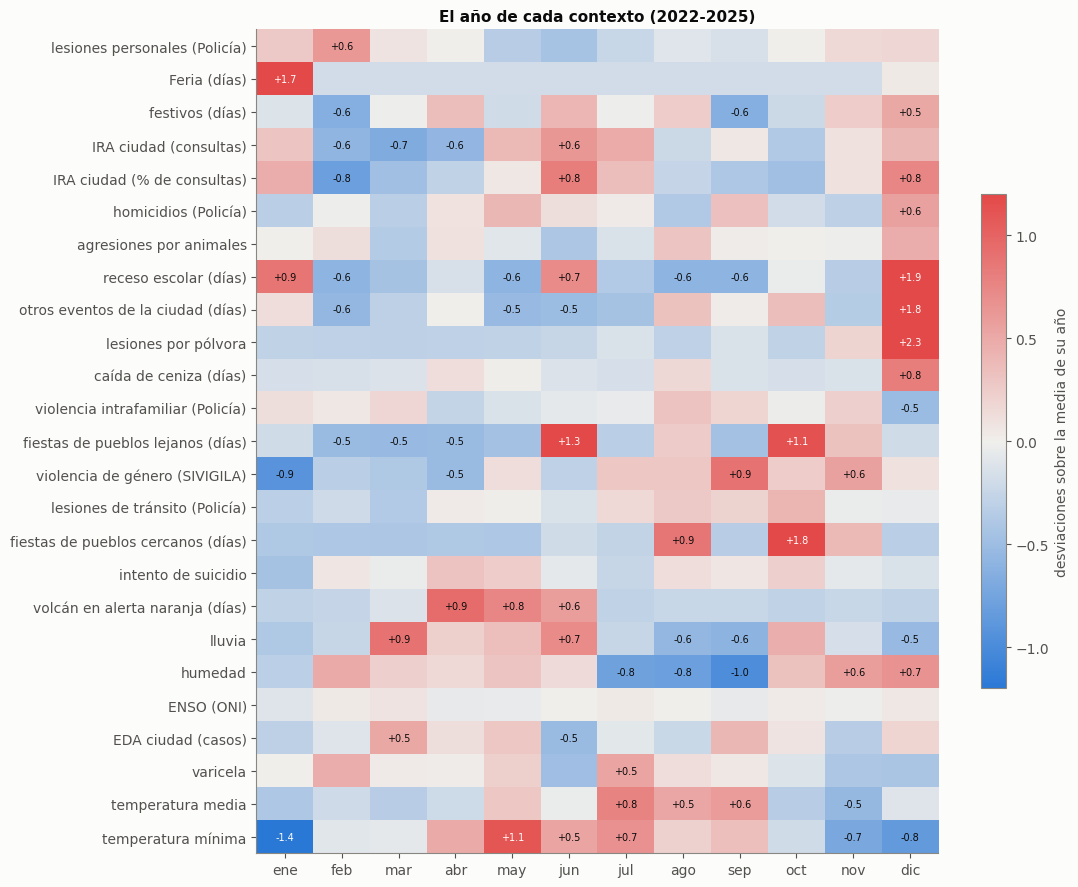

Perfiles anuales más parecidos:
 agresiones por animales            caída de ceniza (días)               0.71
receso escolar (días)              lesiones por pólvora                 0.73
agresiones por animales            otros eventos de la ciudad (días)    0.74
IRA ciudad (% de consultas)        receso escolar (días)                0.75
otros eventos de la ciudad (días)  lesiones por pólvora                 0.83
                                   caída de ceniza (días)               0.85
lesiones por pólvora               caída de ceniza (días)               0.87
IRA ciudad (consultas)             IRA ciudad (% de consultas)          0.88

Más opuestos:
 humedad                        temperatura media                   -0.76
agresiones por animales        lluvia                              -0.75
homicidios (Policía)           violencia intrafamiliar (Policía)   -0.74
lesiones personales (Policía)  temperatura mínima                  -0.68
caída de ceniza (días)         violencia in

In [3]:
from scipy.cluster.hierarchy import linkage, leaves_list
W = E.loc["2022-01-02":"2025-12-28"]
continuas = [c for c in W.columns if W[c].notna().sum() > 150 and W[c].std() > 0]
perfil = {}
for c in continuas:
    s = W[c]
    z = (s - s.groupby(s.index.year).transform("mean")) / s.std()
    perfil[c] = z.groupby(z.index.month).mean()
P = pd.DataFrame(perfil).T
P.columns = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
orden = leaves_list(linkage(P.fillna(0).values, "average", metric="correlation"))
P = P.iloc[orden]
fig, ax = plt.subplots(figsize=(11, 0.38 * len(P) + 1.2))
im = ax.imshow(P.values, cmap=DIVERGENTE, vmin=-1.2, vmax=1.2, aspect="auto")
ax.set_xticks(range(12), P.columns); ax.set_yticks(range(len(P)), P.index); ax.grid(False)
for i in range(P.shape[0]):
    for j in range(P.shape[1]):
        v = P.iat[i, j]
        if abs(v) >= .5: ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=7, color=TINTA if abs(v) < 1 else SUP)
fig.colorbar(im, ax=ax, shrink=.6, label="desviaciones sobre la media de su año")
ax.set_title("El año de cada contexto (2022-2025)"); plt.show()
cor_perfil = P.T.corr()
pares = (cor_perfil.where(np.triu(np.ones(cor_perfil.shape), 1).astype(bool)).stack().sort_values())
print("Perfiles anuales más parecidos:\n", pares.tail(8).round(2).to_string())
print("\nMás opuestos:\n", pares.head(6).round(2).to_string())


## Lectura

**Lo que comparte el año, y dos trampas.**

- **Lo físico va como se espera.** La temperatura y la humedad tienen años opuestos (r = −0,76):
  los meses más cálidos son los más secos del aire.
- **La IRA como porcentaje de consultas sube en los meses de receso escolar** (r = 0,75 entre sus
  perfiles). **Trampa: es sobre todo el denominador.** En receso, la consulta programada cae y la
  IRA pesa más en lo que queda. Por eso para el contagio se usa el **conteo** de IRA, no el
  porcentaje.
- **La violencia intrafamiliar y los homicidios tienen años opuestos** (r = −0,74). La violencia
  en casa y la violencia en la calle no suben en los mismos meses.
- **Trampa de pocos datos:** caída de ceniza, pólvora y «otros eventos» salen con perfiles casi
  idénticos (r = 0,85-0,87). No es una relación: **la ceniza registrada cae en diciembre de 2023**,
  igual que la pólvora y el alumbrado. Con 4 episodios de ceniza, cualquier coincidencia de mes
  parece un patrón.

**Límite.** Son perfiles medios de 4 años. Dicen «pasan en la misma época del año», no «uno
causa al otro». Para eso está la sección 4.

---
# 3. Cómo el calendario mueve la violencia y las lesiones

Series **diarias** de la Policía (2015-2026, sin 2020-03 a 2021-06, que fueron cuarentenas y restricciones). Regresión de Poisson: día de la semana, festivo, quincena, noches festivas de diciembre y enero, Feria y receso escolar, con el año como efecto fijo. Cada barra es la **razón de tasas** contra un día normal: 1,5 = +50 %.

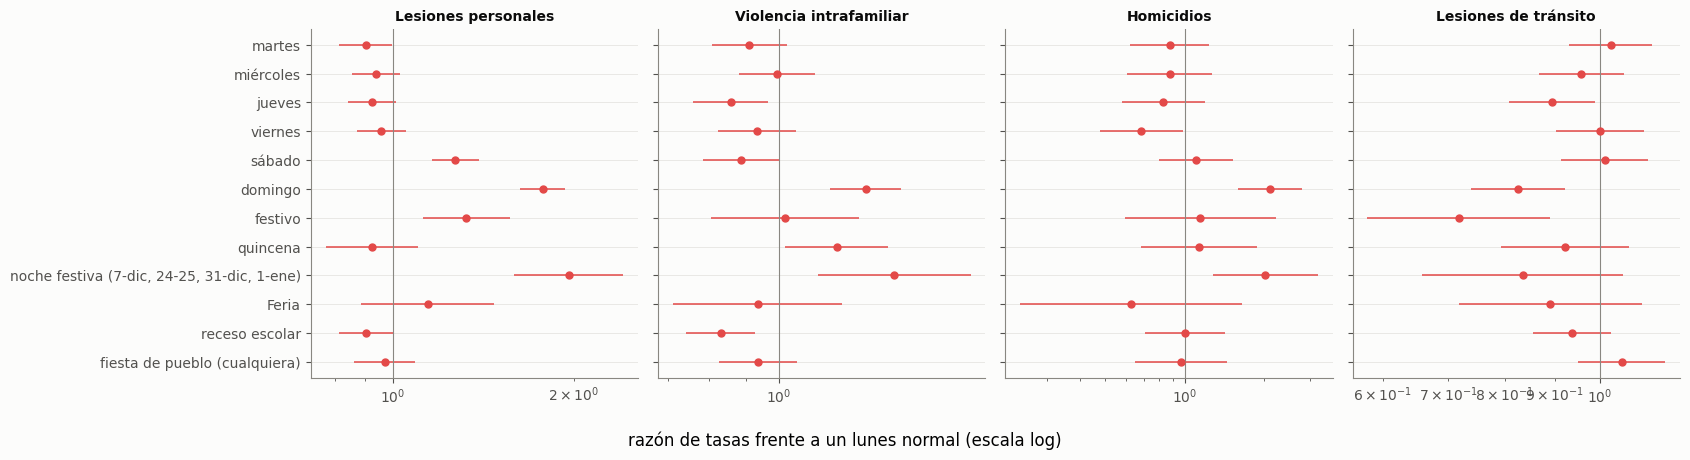

serie,Lesiones personales,Violencia intrafamiliar,Homicidios,Lesiones de tránsito
factor,,,,
martes,0.90,0.91,0.88,1.03
miércoles,0.94,1.00,0.88,0.96
jueves,0.92,0.86,0.83,0.89
viernes,0.96,0.93,0.68,1.00
sábado,1.27,0.89,1.10,1.01
domingo,1.78,1.32,2.11,0.83
festivo,1.32,1.02,1.15,0.72
quincena,0.92,1.20,1.14,0.92
"noche festiva (7-dic, 24-25, 31-dic, 1-ene)",1.96,1.45,2.02,0.83


In [4]:
D = pd.DataFrame(index=dias)
D["dow"] = dias.dayofweek
D["festivo"] = calc.es_festivo.fillna(0).values
D["quincena"] = calc.es_quincena.fillna(0).values
md_ = pd.Series(list(zip(dias.month, dias.day)), index=dias)
D["noche festiva (7-dic, 24-25, 31-dic, 1-ene)"] = md_.isin([(12, 7), (12, 8), (12, 24), (12, 25), (12, 31), (1, 1)]).astype(float).values
D["Feria"] = feria.values
D["receso escolar"] = receso.values
D["fiesta de pueblo (cualquiera)"] = ((fiesta_lejos + fiesta_cerca) > 0).astype(float).values
fuera = ~dias.to_series().between("2020-03-01", "2021-06-30").values
X = pd.concat([pd.get_dummies(D.dow, prefix="d", drop_first=True).astype(float),
               D.drop(columns="dow"), pd.get_dummies(pd.Index(dias.year), prefix="a", drop_first=True).set_index(dias).astype(float)], axis=1)
X.insert(0, "c", 1.0)
nombres_dow = {"d_1": "martes", "d_2": "miércoles", "d_3": "jueves", "d_4": "viernes", "d_5": "sábado", "d_6": "domingo"}
filas = []
for col, nom in [("lesiones_personales", "Lesiones personales"), ("violencia_intrafamiliar", "Violencia intrafamiliar"),
                 ("homicidio", "Homicidios"), ("lesiones_transito", "Lesiones de tránsito")]:
    y = seg[col]; ok = fuera & y.notna().values
    xx = X[ok].copy()
    if col != "lesiones_transito": pass
    m = sm.GLM(y[ok], xx, family=sm.families.Poisson()).fit(cov_type="HC0")
    for v_ in list(nombres_dow) + [c for c in D.columns if c != "dow"]:
        if v_ in m.params:
            b, s_ = m.params[v_], m.bse[v_]
            filas.append({"serie": nom, "factor": nombres_dow.get(v_, v_), "razón": np.exp(b), "bajo": np.exp(b - 1.96 * s_), "alto": np.exp(b + 1.96 * s_)})
T3 = pd.DataFrame(filas)
series_ = T3.serie.unique()
fig, axes = plt.subplots(1, len(series_), figsize=(17, 4.6), sharey=True)
factores = list(dict.fromkeys(T3.factor))
for ax, s in zip(axes, series_):
    g = T3[T3.serie.eq(s)].set_index("factor").reindex(factores)
    y = range(len(factores))
    ax.errorbar(g["razón"], y, xerr=[g["razón"] - g.bajo, g.alto - g["razón"]], fmt="o", color=ROJO, ms=5, lw=1.1)
    ax.axvline(1, color=MUDO, lw=.8); ax.set_xscale("log"); ax.set_title(s, fontsize=10)
axes[0].set_yticks(range(len(factores)), factores); axes[0].invert_yaxis()
fig.supxlabel("razón de tasas frente a un lunes normal (escala log)"); plt.tight_layout(); plt.show()
T3.pivot_table(index="factor", columns="serie", values="razón", sort=False).reindex(factores).round(2)


## Lectura

**El calendario sí mueve la violencia de la ciudad, y mucho** (Policía, 2015-2026, sin el periodo de
cuarentenas). Razón de tasas frente a un lunes normal:

| | Lesiones personales | Violencia intrafamiliar | Homicidios | Tránsito |
|---|---|---|---|---|
| **Domingo** | **×1,78** | **×1,32** | **×2,11** | ×0,83 |
| Sábado | ×1,27 | ×0,89 | ×1,10 | ×1,01 |
| **Festivo** | **×1,32** | ×1,02 | ×1,15 | **×0,72** |
| **Noche festiva** (7-dic, 24-25, 31-dic, 1-ene) | **×1,96** | **×1,45** | **×2,02** | ×0,83 |
| **Quincena** | ×0,92 | **×1,20** | ×1,14 | ×0,92 |
| Receso escolar | ×0,90 | **×0,83** | ×1,00 | ×0,94 |
| Feria | ×1,14 | ×0,93 | ×0,63 | ×0,89 |

- **Las lesiones y los homicidios son de domingo y de noche festiva.** Las noches de diciembre y
  enero casi duplican las lesiones y los homicidios de un día normal. Es la «fiesta peligrosa» que
  describía el propietario, medida en la ciudad.
- **La violencia intrafamiliar tiene otro calendario:** sube en **quincena** (×1,20), el día de
  pago, y **baja en receso escolar** (×0,83). Otra dinámica, dentro de la casa.
- **El tránsito baja en festivo y domingo:** hay menos gente circulando.
- **La Feria no se distingue** con estos intervalos (lesiones ×1,14, con un intervalo que cruza el
  1).

**Límite.** Es lo que se **denuncia** a la Policía. Las lesiones que no se denuncian, que en
fiestas pueden ser muchas, no están.

---
# 4. Cadenas con rezago

**Anomalías semanales**: cada serie sin su nivel del año y sin su forma estacional típica, para no confundir «pasan en la misma época» con «uno empuja al otro». Correlación del factor en la semana *t* con la respuesta en la semana *t + k*, con *k* de −4 a +8. Un pico en *k > 0* es compatible con que el factor **precede** a la respuesta. La banda gris es el umbral aproximado de significación (Bartlett). Ventana 2022-2025. Las cadenas son las que la literatura espera (sección 6).

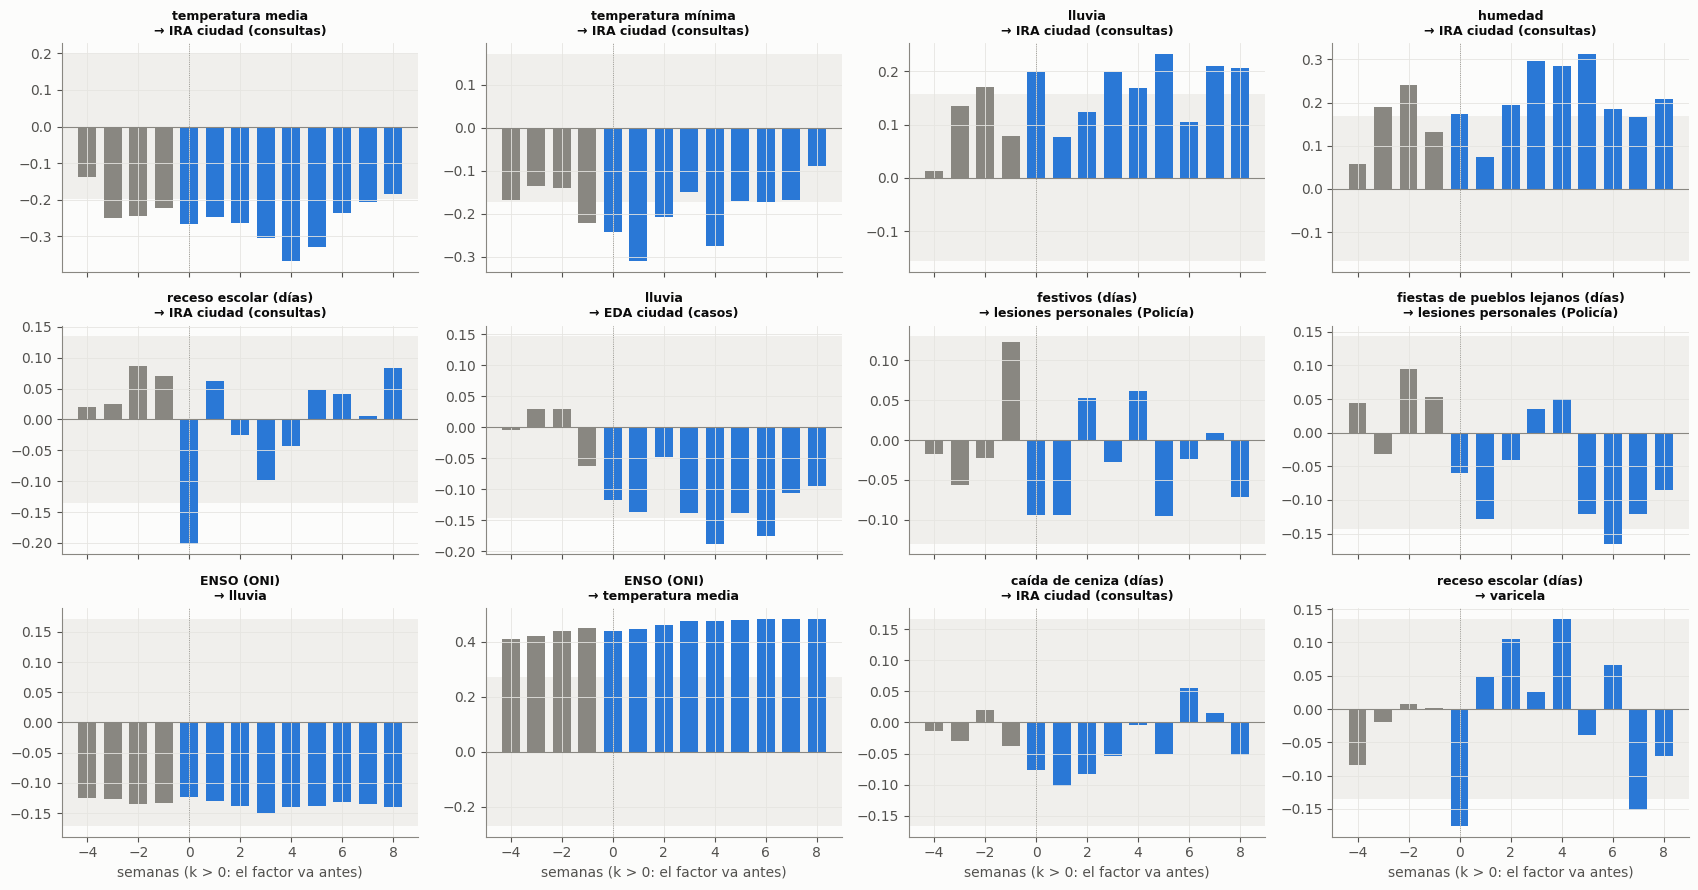

,factor,respuesta,r máximo,en semana,umbral,n efectivo
0,temperatura media,IRA ciudad (consultas),-0.37,4,0.20,100
1,temperatura mínima,IRA ciudad (consultas),-0.31,1,0.17,132
2,lluvia,IRA ciudad (consultas),0.23,5,0.16,159
3,humedad,IRA ciudad (consultas),0.31,5,0.17,139
4,receso escolar (días),IRA ciudad (consultas),-0.20,0,0.13,214
5,lluvia,EDA ciudad (casos),-0.19,4,0.15,181
6,festivos (días),lesiones personales (Policía),0.12,-1,0.13,230
7,fiestas de pueblos lejanos (días),lesiones personales (Policía),-0.17,6,0.14,189
8,ENSO (ONI),lluvia,-0.15,3,0.17,133
9,ENSO (ONI),temperatura media,0.49,6,0.27,55


In [5]:
def anomalia(s):
    s = s.dropna()
    s = s - s.groupby(s.index.year).transform("mean")
    return s - s.groupby(s.index.isocalendar().week.values).transform("mean")

W = E.loc["2022-01-02":"2025-12-28"]
cadenas = [("temperatura media", "IRA ciudad (consultas)"), ("temperatura mínima", "IRA ciudad (consultas)"),
           ("lluvia", "IRA ciudad (consultas)"), ("humedad", "IRA ciudad (consultas)"),
           ("receso escolar (días)", "IRA ciudad (consultas)"), ("lluvia", "EDA ciudad (casos)"),
           ("festivos (días)", "lesiones personales (Policía)"), ("fiestas de pueblos lejanos (días)", "lesiones personales (Policía)"),
           ("ENSO (ONI)", "lluvia"), ("ENSO (ONI)", "temperatura media"),
           ("caída de ceniza (días)", "IRA ciudad (consultas)"), ("receso escolar (días)", "varicela")]
LAGS = range(-4, 9)
fig, axes = plt.subplots(3, 4, figsize=(17, 9), sharex=True)
res4 = []
for ax, (x, y) in zip(axes.ravel(), cadenas):
    if x not in W or y not in W or W[x].std() == 0:
        ax.set_visible(False); continue
    ax_ = anomalia(W[x]) if not x.startswith("ENSO") else (W[x] - W[x].mean())
    ay = anomalia(W[y])
    rs = [ax_.corr(ay.shift(-k)) for k in LAGS]
    n = pd.concat([ax_, ay], axis=1).dropna().shape[0]
    a1, a2 = ax_.autocorr(), ay.autocorr()
    neff = n * (1 - a1 * a2) / (1 + a1 * a2)
    um = 1.96 / np.sqrt(max(neff - 3, 4))
    ax.axhspan(-um, um, color="#f0efec", lw=0); ax.axhline(0, color=MUDO, lw=.8); ax.axvline(0, color=MUDO, lw=.6, ls=":")
    ax.bar(list(LAGS), rs, color=[AZUL if k >= 0 else MUDO for k in LAGS], width=.7)
    ax.set_title(f"{x}\n→ {y}", fontsize=9)
    kbest = list(LAGS)[int(np.nanargmax(np.abs(rs)))]
    res4.append({"factor": x, "respuesta": y, "r máximo": round(rs[list(LAGS).index(kbest)], 2), "en semana": kbest,
                 "umbral": round(um, 2), "n efectivo": int(neff)})
for ax in axes[-1]: ax.set_xlabel("semanas (k > 0: el factor va antes)")
plt.tight_layout(); plt.show()
pd.DataFrame(res4)


## Lectura

**Aparece la cadena que el propietario describía: el clima precede a la circulación de virus en
la ciudad.** Anomalías semanales, 2022-2025, sin el nivel del año ni la forma estacional típica:

| Factor → respuesta | r máximo | Semanas después | Umbral |
|---|---|---|---|
| **Temperatura media → IRA ciudad** | **−0,37** | **4** | 0,20 |
| **Temperatura mínima → IRA ciudad** | **−0,31** | **1** | 0,17 |
| **Humedad → IRA ciudad** | **+0,31** | **5** | 0,17 |
| **Lluvia → IRA ciudad** | **+0,23** | **5** | 0,16 |
| **Receso escolar → IRA ciudad** | **−0,20** | **0** | 0,13 |
| **Receso escolar → varicela** | **−0,18** | **0** | 0,14 |
| **ENSO → temperatura** | **+0,49** | 6 (en todas) | 0,27 |
| ENSO → lluvia | −0,15 | 3 | 0,17 |
| Lluvia → EDA | −0,19 | 4 | 0,15 |
| Ceniza → IRA | −0,10 | 1 | 0,17 |

1. **Una semana más fría de lo normal para su época va seguida de más IRA en la ciudad 1 a 5
   semanas después.** Una semana más húmeda o más lluviosa, también, a 3-5 semanas. Es el
   mecanismo «frío y humedad → contagio → consulta» con su incubación, visto en la ciudad y sin
   el hospital.
   - **Cuidado:** las barras de temperatura también son negativas en *k < 0*. Parte de la
     relación es que las rachas frías duran varias semanas y la IRA también. La relación es más
     fuerte hacia delante (pico en +4), pero no es una prueba de causa.
2. **Cerrar los colegios corta la transmisión en la misma semana**: la IRA baja con el receso, y
   la varicela, que es enfermedad de niños en edad escolar, también. Es el efecto de «vuelta a
   clases» visto al revés.
3. **El ENSO calienta Manizales.** Con El Niño, la temperatura sube de forma sostenida (+0,49).
   Con la lluvia la señal va en la dirección esperada (El Niño más seco) pero no pasa el umbral.
4. **La lluvia no precede a más diarrea: va al revés** (−0,19 a 4 semanas). No es lo que se
   esperaba. Puede ser que en Manizales la EDA dependa más del agua y de los alimentos que de la
   lluvia, o que la serie de EDA, con su caída a la mitad desde 2020, no sirva para esto.
5. **La ceniza no se puede medir.** Solo hay 4 episodios registrados a mano.

**Límites.**
- Son 12 cadenas con 13 rezagos cada una, así que alguna barra pasaría el umbral por azar. Se
  leen **la forma y la dirección**, no una barra suelta.
- **La IRA de la ciudad mezcla consulta externa con urgencias.**

---
# 5. Estados del entorno

Cada semana de 2022-2025 descrita por su clima, su vigilancia, su violencia y su calendario, **con** la estacionalidad (un estado puede ser «temporada»). Variables estandarizadas; agrupamiento k-medias con el número de grupos elegido por silueta. Cada estado se nombra por lo que lo distingue de la media. La **calma** es el estado más cercano a la media en todo.

silueta por k: {3: 0.137, 4: 0.159, 5: 0.167, 6: 0.16, 7: 0.126} → k = 5
distancia de cada estado a la media (la calma es la menor): {0: 2.73, 1: 2.12, 2: 7.53, 3: 2.8, 4: 1.25}


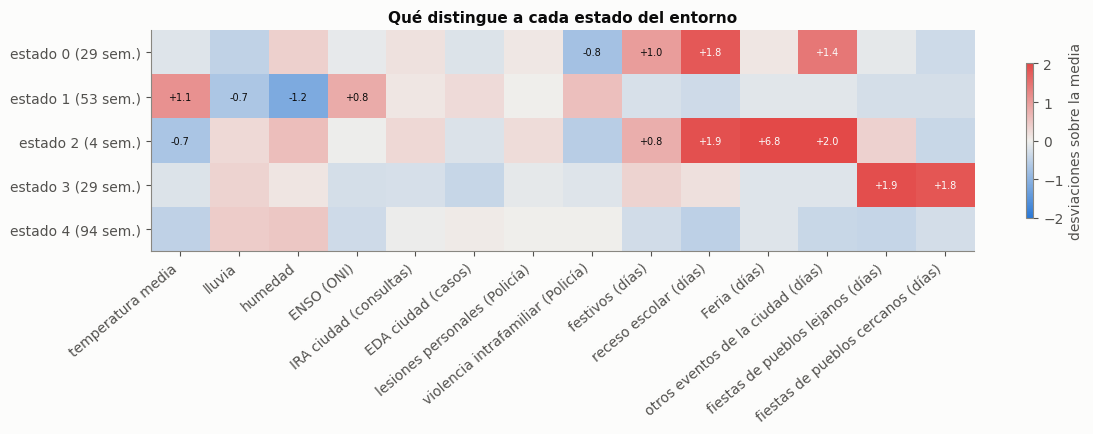

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
feat = ["temperatura media", "lluvia", "humedad", "ENSO (ONI)", "IRA ciudad (consultas)", "EDA ciudad (casos)",
        "lesiones personales (Policía)", "violencia intrafamiliar (Policía)", "festivos (días)", "receso escolar (días)",
        "Feria (días)", "otros eventos de la ciudad (días)", "fiestas de pueblos lejanos (días)", "fiestas de pueblos cercanos (días)"]
X5 = W[feat].copy()
for c in ["IRA ciudad (consultas)", "EDA ciudad (casos)", "lesiones personales (Policía)", "violencia intrafamiliar (Policía)"]:
    X5[c] = X5[c] - X5[c].groupby(X5.index.year).transform("mean")     # sin el nivel del anio (cobertura cambiante)
X5 = X5.dropna()
Z5 = (X5 - X5.mean()) / X5.std()
sil = {k: silhouette_score(Z5, KMeans(k, n_init=20, random_state=0).fit_predict(Z5)) for k in range(3, 8)}
k = max(sil, key=sil.get)
km = KMeans(k, n_init=50, random_state=0).fit(Z5)
estado = pd.Series(km.labels_, index=Z5.index)
cent = pd.DataFrame(km.cluster_centers_, columns=feat)
dist = np.sqrt((cent ** 2).sum(axis=1))
print("silueta por k:", {kk: round(v, 3) for kk, v in sil.items()}, "→ k =", k)
print("distancia de cada estado a la media (la calma es la menor):", dist.round(2).to_dict())
fig, ax = plt.subplots(figsize=(12, 0.45 * k + 2.2))
im = ax.imshow(cent.values, cmap=DIVERGENTE, vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(k), [f"estado {i} ({(estado == i).sum()} sem.)" for i in range(k)])
ax.set_xticks(range(len(feat)), feat, rotation=40, ha="right"); ax.grid(False)
for i in range(k):
    for j in range(len(feat)):
        v_ = cent.iat[i, j]
        if abs(v_) >= .6: ax.text(j, i, f"{v_:+.1f}", ha="center", va="center", fontsize=7, color=TINTA if abs(v_) < 1.3 else SUP)
fig.colorbar(im, ax=ax, shrink=.7, label="desviaciones sobre la media"); ax.set_title("Qué distingue a cada estado del entorno")
plt.tight_layout(); plt.show()


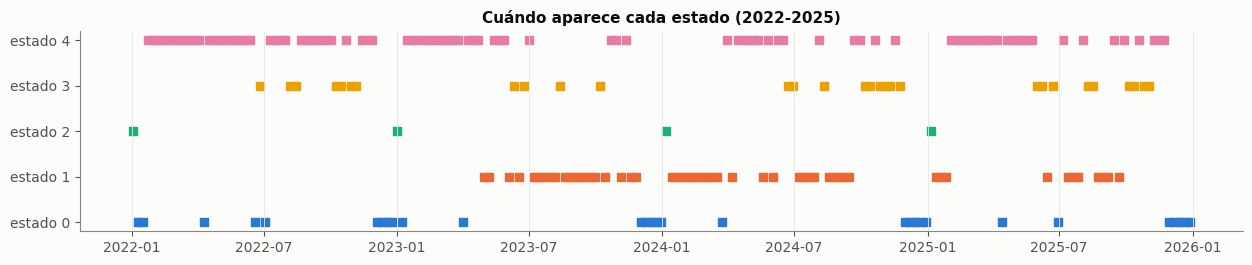

,estado 0,estado 1,estado 2,estado 3,estado 4
ene,17.0,33.0,22.0,0.0,28.0
feb,0.0,25.0,0.0,0.0,75.0
mar,6.0,17.0,0.0,0.0,78.0
abr,18.0,12.0,0.0,0.0,71.0
may,0.0,12.0,0.0,0.0,88.0
jun,11.0,22.0,0.0,44.0,22.0
jul,6.0,61.0,0.0,0.0,33.0
ago,0.0,41.0,0.0,35.0,24.0
sep,0.0,53.0,0.0,0.0,47.0
oct,0.0,11.0,0.0,56.0,33.0


In [7]:
fig, ax = plt.subplots(figsize=(15, 2.6))
for i in range(k):
    s = estado[estado == i]
    ax.scatter(s.index, [i] * len(s), marker="s", s=40, color=CATEG[i % 8], label=f"estado {i}")
ax.set_yticks(range(k), [f"estado {i}" for i in range(k)]); ax.set_title("Cuándo aparece cada estado (2022-2025)")
ax.grid(axis="y", visible=False); plt.show()
por_mes = pd.crosstab(estado.index.month, estado, normalize="index").mul(100).round(0)
por_mes.index = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"][:len(por_mes)]
por_mes.columns = [f"estado {i}" for i in por_mes.columns]
por_mes


## Lectura

**Con el calendario incluido, el entorno se agrupa en cinco estados, y la «calma» es el más común.**

| Estado | Semanas | Qué lo distingue | Cuándo aparece |
|---|---|---|---|
| **4 · Calma** | **94 (45 %)** | Nada se aparta de la media: colegios en clase, sin fiestas | **Febrero a mayo (71-88 %)** y septiembre-noviembre |
| 1 · Seco y cálido | 53 | Temperatura +1,1, humedad −1,2, lluvia −0,7, ENSO +0,8 | **Julio-septiembre** y El Niño de 2023-24 |
| 3 · Fiestas de los pueblos | 29 | Fiestas lejanas +1,9 y cercanas +1,8 | Junio, agosto, octubre-noviembre |
| 0 · Temporada decembrina | 29 | Receso escolar +1,8, eventos +1,4, festivos +1,0 | **Diciembre (100 %)** |
| 2 · Feria | 4 | Feria +6,8, eventos +2,0, receso +1,9 | Primera semana de enero |

- **La calma existe, tiene fecha y es lo normal.** Febrero-mayo y septiembre-noviembre son semanas
  en que nada se sale de lo habitual: colegios abiertos, sin fiestas y clima promedio.
- **Diciembre es un estado propio todos los años**, y la Feria otro.
- **La circulación de virus y la violencia no definen ningún estado.** Esas columnas quedan cerca
  de cero en todos. El calendario manda en este agrupamiento porque sus variables son muy marcadas.
  Por eso la sección 5.1 agrupa sin calendario.

**Límite.** La silueta es baja (0,17): los estados no son grupos nítidos, sino zonas de un
continuo. Sirven para describir y nombrar, no como categorías exactas.

## 5.1 Solo lo natural: clima, virus, diarrea y violencia

En el agrupamiento anterior mandan las variables de calendario, que son muy marcadas (una semana de Feria está a +6,8 desviaciones). Aquí se agrupa **sin el calendario**, solo con lo que no se decreta: clima, ENSO, IRA, EDA y violencia. Así se ve si existe una «temporada respiratoria» como estado propio, y después se mira con qué calendario coincide.

silueta por k: {3: 0.136, 4: 0.134, 5: 0.132, 6: 0.131} → k = 3


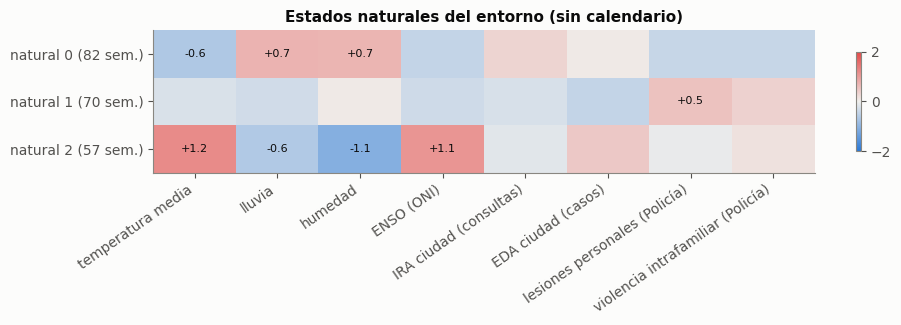

,natural 0,natural 1,natural 2
ene,28.0,50.0,22.0
feb,19.0,56.0,25.0
mar,67.0,11.0,22.0
abr,47.0,41.0,12.0
may,59.0,24.0,18.0
jun,56.0,28.0,17.0
jul,33.0,6.0,61.0
ago,6.0,47.0,47.0
sep,24.0,35.0,41.0
oct,44.0,33.0,22.0


con calendario,0,1,2,3,4
natural,,,,,
0,12,0,3,11,56
1,11,11,0,12,36
2,6,42,1,6,2


In [8]:
nat = ["temperatura media", "lluvia", "humedad", "ENSO (ONI)", "IRA ciudad (consultas)", "EDA ciudad (casos)",
       "lesiones personales (Policía)", "violencia intrafamiliar (Policía)"]
Zn = Z5[nat]
siln = {kk: silhouette_score(Zn, KMeans(kk, n_init=20, random_state=0).fit_predict(Zn)) for kk in range(3, 7)}
kn = max(siln, key=siln.get)
kmn = KMeans(kn, n_init=50, random_state=0).fit(Zn)
estado_n = pd.Series(kmn.labels_, index=Zn.index)
centn = pd.DataFrame(kmn.cluster_centers_, columns=nat)
print("silueta por k:", {kk: round(v, 3) for kk, v in siln.items()}, "→ k =", kn)
fig, ax = plt.subplots(figsize=(10, 0.45 * kn + 2))
im = ax.imshow(centn.values, cmap=DIVERGENTE, vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(kn), [f"natural {i} ({(estado_n == i).sum()} sem.)" for i in range(kn)])
ax.set_xticks(range(len(nat)), nat, rotation=35, ha="right"); ax.grid(False)
for i in range(kn):
    for j in range(len(nat)):
        v_ = centn.iat[i, j]
        if abs(v_) >= .5: ax.text(j, i, f"{v_:+.1f}", ha="center", va="center", fontsize=8, color=TINTA if abs(v_) < 1.3 else SUP)
fig.colorbar(im, ax=ax, shrink=.7); ax.set_title("Estados naturales del entorno (sin calendario)"); plt.tight_layout(); plt.show()
cruce = pd.crosstab(estado_n.rename("natural"), estado.rename("con calendario"))
mes_n = pd.crosstab(estado_n.index.month, estado_n, normalize="index").mul(100).round(0)
mes_n.index = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"][:len(mes_n)]
mes_n.columns = [f"natural {i}" for i in mes_n.columns]
display(mes_n)
cruce


## Lectura

**Sin el calendario, el entorno natural tiene tres estados, y son las estaciones de Manizales:**

| Estado natural | Semanas | Qué lo distingue | Cuándo |
|---|---|---|---|
| **0 · Frío y húmedo** | 82 | Temperatura −0,6, lluvia +0,7, humedad +0,7 | **Marzo a junio** (47-67 %) y **octubre a diciembre** (41-44 %): las dos temporadas de lluvia |
| 1 · Intermedio | 70 | Clima medio, lesiones +0,5 | Enero-febrero, agosto y noviembre |
| **2 · Seco y cálido** | 57 | Temperatura +1,2, humedad −1,1, lluvia −0,6, ENSO +1,1 | **Julio a septiembre** y El Niño |

- **La «temporada respiratoria» no aparece como estado aparte.** La IRA de la ciudad no se separa
  en ningún grupo. Lo que sí hay es **el estado frío y húmedo**, que según la sección 4 **precede**
  a la IRA en 1-5 semanas. Es decir: el estado que se ve es el **gatillo** (frío y húmedo), no la
  consecuencia.
- **El cruce con los estados del calendario** muestra cómo se superponen:
  - de las 94 semanas de «calma» de calendario, **56 son frías y húmedas**. La calma de marzo a
    mayo es tranquila en calendario, pero **no en clima**;
  - de las 57 semanas secas y cálidas, 42 caen en el estado «seco y cálido» del calendario.
- **Esto es la «suma de factores» del propietario, puesta en fechas.** **Marzo a mayo** junta
  colegios abiertos (contagio), clima frío y húmedo (gatillo) y temporada de lluvias. El cuaderno
  08 vio justamente ahí las semanas altas sostenidas del triage. **Diciembre** junta receso
  escolar (menos contagio), fiestas, alcohol y violencia: los picos puntuales de noche.

**Límite.** La silueta es baja (0,13). Son tres regiones de un continuo climático, no tres cajas.

---
# 6. Lo observado contra lo publicado

La revisión está en `calendarios/docs/LITERATURA_ENTORNO.md`. Tiene 11 relaciones y 86 referencias
leídas al menos en su resumen (marca [V]); lo visto solo en el buscador lleva [B]. **Se escribió
antes de comparar**, para que lo esperado no se ajustara a lo observado.

| Relación | Lo publicado | Lo observado en Manizales | ¿Coincide? |
|---|---|---|---|
| **Lluvia y humedad → IRA** | +, rezago 0-1 mes (VSR en Bogotá) | **Lluvia +0,23 y humedad +0,31 a 5 semanas** | **Sí**, en dirección y rezago |
| **Temperatura → IRA** | Signo inestable en los Andes: en Bogotá, +, porque sus meses cálidos son los lluviosos; −, en el metaanálisis global | **Frío → más IRA: −0,37 a 4 semanas** | Coincide con el global. En Manizales, frío y lluvia van juntos |
| **Cambio brusco de temperatura → consultas** | +1,44 % por °C, 0-21 días | Cuaderno 07: enfriamiento → +2 a +4 % en mayores y adultos en día laboral, a 1-3 semanas, sin significancia | **En dirección** |
| **Cierre de colegios → transmisión** | −20 a −37 %; rebrote 2-5 semanas tras reabrir | **Receso → IRA −0,20 y varicela −0,18 la misma semana**; rebrote no visible | **Sí en la bajada**. Más rápida de lo publicado: puede que parte sea que se consulta menos, no solo que se contagia menos |
| **ENSO → clima** | El Niño: más calor y menos lluvia, 2-4 meses | **ENSO → temperatura +0,49**; lluvia −0,15, sin pasar el umbral | **Sí** en temperatura; débil en lluvia |
| **Ceniza → IRA y asma** | RR 2,2 en Quito, 0-3 semanas | **No se puede medir**: 4 episodios escritos a mano, sin PM10 | **Vacío de datos** |
| **Fin de semana, festivo y alcohol → violencia** | Alta: domingo 20 % de los homicidios | **Domingo ×1,78 lesiones y ×2,11 homicidios; noche festiva ×1,96 y ×2,02** | **Sí, fuerte** |
| **Quincena → violencia** | **Sin estudio publicado** | **Violencia intrafamiliar ×1,20 en quincena**; lesiones sin efecto | **Aporte propio** |
| **Pólvora → quemados** | Concentración 1-dic a 17-ene | 80 % de los casos en diciembre-enero | **Sí** |
| **Lluvia → siniestros viales** | +38 % por hora de lluvia | Cuaderno 07: sin aumento diario, ni en la ciudad ni en el SES | **No**, pero la literatura avisa que el dato diario diluye un efecto que es por hora |
| **Lluvia → EDA** | + tras un periodo seco; − en plena temporada húmeda | **Anomalía de lluvia → EDA −0,19 a 4 semanas** | Coincide con la mitad «−»; la transición seco → lluvioso sobre la EDA no se midió |
| **Frío → cardiorrespiratorio en mayores** | +3,4 % de muertes por °C, 0-21 días | Cuaderno 07: enfriamiento → 65+ +4,2 % a 14-20 días, sin significancia | **En dirección** |
| **Eventos masivos** | Lesiones +; respiratorio pequeño | Feria: lesiones de la Policía ×1,14 sin significancia; SOAT del SES +37 % (07) | **Sí en lesiones**, con la huella en el hospital |
| **Interacciones frío × virus × edad** | **Sin estimación para la región** | No medida todavía | **Pregunta abierta: aporte posible** |

**Lectura.**
1. **Casi todo lo que se esperaba aparece, en la dirección publicada.** La cadena «frío y humedad →
   contagio a 1-5 semanas», el efecto de los colegios, el calor de El Niño y la violencia de
   domingos y noches festivas. El entorno de Manizales se comporta como dice la literatura. Eso
   da confianza en que las series externas están midiendo lo que dicen medir.
2. **Dos resultados no tienen estudio publicado y serían aporte de la tesis:**
   - **la quincena mueve la violencia intrafamiliar** (×1,20);
   - **la interacción frío × virus × población mayor**, que la literatura deja abierta y que es
     exactamente la «suma de factores» del propietario.
3. **Tres vacíos son de datos, no de mecanismo:**
   - **ceniza**: haría falta el PM10 diario del CDIAC, que la red institucional bloquea (#10a);
   - **lluvia y tránsito**: haría falta el dato por hora;
   - **transición seco → lluvioso sobre la EDA**.
4. **Los estados del entorno se parecen a los que sugiere la literatura, con una diferencia.** La
   revisión propone cinco candidatos: respiratorio, festivo, calma, anomalía ENSO y episodio
   volcánico. Aquí se vieron:
   - calma, festivo (diciembre y Feria) y un estado seco y cálido donde **El Niño amplifica**,
     como predice la literatura;
   - **no apareció un estado «respiratorio», sino su gatillo**, el frío y húmedo, que precede a la
     IRA;
   - el volcánico no se puede ver con los datos que hay.

**Siguiente paso.** Enfrentar contra el hospital **los estados y sus combinaciones**, con las
interacciones preregistradas antes de mirar. La primera es la del propietario: frío anómalo ×
IRA circulando × mayores de 65.